In [3]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import time

In [11]:
# ===============================================================
# ===================== CLASSE E FUNÇÕES BÁSICAS =================
# ===============================================================

class Problema:
    """
    Classe que representa o problema do caixeiro viajante (TSP)
    com dois objetivos: distância e tempo.
    Ela lê as matrizes de distância e tempo e guarda o número de cidades.
    """
    def __init__(self, arquivo_distancia, arquivo_tempo):
        # Lê as matrizes de distância e tempo de arquivos CSV
        self.distancia = pd.read_csv(arquivo_distancia, header=None).to_numpy(dtype=float)
        self.tempo     = pd.read_csv(arquivo_tempo,     header=None).to_numpy(dtype=float)
        self.n = self.distancia.shape[0]  # número de cidades

    def custo_arco(self, i, j, objetivo):
        # Retorna o custo do arco (i → j) dependendo do objetivo escolhido
        if objetivo == "distancia":
            return self.distancia[i, j]
        elif objetivo == "tempo":
            return self.tempo[i, j]


def custo_rota(problema, rota, objetivo):
    """
    Calcula o custo total de uma rota, somando os custos
    de todos os arcos (ida e volta à cidade inicial).
    """
    c = 0.0
    for k in range(len(rota) - 1):
        c += problema.custo_arco(rota[k], rota[k+1], objetivo)
    c += problema.custo_arco(rota[-1], rota[0], objetivo)
    return c


def construtiva_vizinho_mais_proximo(problema, objetivo):
    """
    Gera uma solução inicial simples, começando na cidade 0
    e sempre indo para o vizinho mais próximo não visitado.
    Essa é uma construção gulosa usada como ponto de partida.
    """
    n = problema.n
    rota = [0]
    visitado = [False] * n
    visitado[0] = True
    atual = 0

    for _ in range(n - 1):
        proxima_cidade = None
        menor_custo = float("inf")
        for j in range(n):
            if not visitado[j]:
                custo = problema.custo_arco(atual, j, objetivo)
                if custo < menor_custo:
                    menor_custo = custo
                    proxima_cidade = j
        rota.append(proxima_cidade)
        visitado[proxima_cidade] = True
        atual = proxima_cidade
    return rota


# ===============================================================
# ===================== VIZINHANÇAS E DELTAS =====================
# ===============================================================

# Essas funções geram "vizinhanças", ou seja, variações da rota atual
# (técnica comum em metaheurísticas como VNS, GVNS, etc.)

def vizinhanca_adjacent_swap(rota, a):
    """
    Troca duas cidades vizinhas na rota.
    Pequena perturbação — útil para refinar soluções.
    """
    nova = rota[:]
    if a == 0 or a >= len(rota) - 1:
        return nova
    nova[a], nova[a+1] = nova[a+1], nova[a]
    return nova


def vizinhanca_2opt(rota, a, b):
    """
    Inverte o segmento da rota entre as posições a e b.
    Muito usada no TSP para eliminar cruzamentos.
    """
    if a == 0 or b == 0 or a >= b:
        return rota[:]
    return rota[:a] + rota[a:b+1][::-1] + rota[b+1:]


def vizinhanca_oropt1(rota, a, b):
    """
    Remove a cidade da posição 'a' e a reinsere antes da posição 'b'.
    Isso permite deslocar blocos pequenos da rota.
    """
    if a == 0 or b == 0 or b == a or b == a + 1:
        return rota[:]
    nova = rota.copy()
    cidade = nova.pop(a)
    if b >= len(nova):
        nova.append(cidade)
    else:
        nova.insert(b, cidade)
    return nova


# ===============================================================
# ==================== FUNÇÕES AUXILIARES ========================
# ===============================================================

def shake(rota, k):
    """
    Aplica uma perturbação aleatória na solução atual.
    Isso ajuda o algoritmo a escapar de mínimos locais.
    O tipo de perturbação depende do valor de k.
    """
    n = len(rota)
    if k == 1:
        a = random.randint(1, n-2)
        return vizinhanca_adjacent_swap(rota, a)
    elif k == 2:
        a = random.randint(1, n-3)
        b = random.randint(a+1, n-1)
        return vizinhanca_2opt(rota, a, b)
    elif k == 3:
        while True:
            a = random.randint(1, n-2)
            b = random.randint(1, n-1)
            if b != a and b != a + 1:
                break
        return vizinhanca_oropt1(rota, a, b)


def neighborhood_change(rota, custo, rota_cand, custo_cand, k):
    """
    Decide se a solução candidata substitui a atual.
    Se sim, reinicia as vizinhanças; se não, avança para a próxima.
    """
    if custo_cand < custo - 1e-12:
        return rota_cand, custo_cand, 1
    else:
        return rota, custo, k + 1


# ===============================================================
# =================== SOMA PONDERADA (W-SUM) =====================
# ===============================================================

def custo_ponderado(problema, rota, w1, w2):
    """
    Calcula o custo combinado de uma rota
    segundo o método da soma ponderada:
    custo = w1 * distância + w2 * tempo
    """
    return w1 * custo_rota(problema, rota, "distancia") + w2 * custo_rota(problema, rota, "tempo")


def normalizar_pesos(w1, w2):
    """
    Garante que a soma dos pesos seja 1.
    Isso evita distorções quando o usuário define valores arbitrários.
    """
    total = w1 + w2
    return w1 / total, w2 / total


def gvns_soma_ponderada(problema, rota_inicial, w1, w2, lmax=1, kmax=3, max_iter=200, seed=None):
    """
    Implementa o método GVNS (General Variable Neighborhood Search)
    adaptado para o problema biobjetivo usando a soma ponderada.
    """
    if seed is not None:
        random.seed(seed)

    w1, w2 = normalizar_pesos(w1, w2)
    rota_atual = rota_inicial[:]
    custo_atual = custo_ponderado(problema, rota_atual, w1, w2)
    it = 0
    historico = []

    # Estrutura de busca principal
    while it < max_iter:
        k = 1
        while k <= kmax and it < max_iter:
            rota_aleatoria = shake(rota_atual, k)
            custo_aleatoria = custo_ponderado(problema, rota_aleatoria, w1, w2)

            # Se melhorou, aceita e reinicia vizinhanças
            if custo_aleatoria < custo_atual:
                rota_atual, custo_atual = rota_aleatoria, custo_aleatoria
                k = 1
            else:
                k += 1

            it += 1
            historico.append((it, custo_atual))

    return rota_atual, custo_atual, historico


# ===============================================================
# ===================== ε-RESTRITO (EPSILON) =====================
# ===============================================================

def gvns_epsilon(problema, rota_inicial, epsilon, lmax=1, kmax=3, max_iter=200):
    """
    Implementa o GVNS para o método ε-restrito.
    Minimiza a distância com a restrição de tempo ≤ ε.
    """
    # Garante que a solução inicial respeite a restrição
    while custo_rota(problema, rota_inicial, "tempo") > epsilon:
        rota_inicial = shake(rota_inicial, k=1)

    rota_atual = rota_inicial[:]
    custo_atual = custo_rota(problema, rota_atual, "distancia")
    melhor_rota, melhor_custo, melhor_tempo = None, float("inf"), None
    historico = []
    it = 0

    while it < max_iter:
        k = 1
        while k <= kmax and it < max_iter:
            rota_aleatoria = shake(rota_atual, k)
            custo_melhor_local = custo_rota(problema, rota_aleatoria, "distancia")
            tempo_total = custo_rota(problema, rota_aleatoria, "tempo")

            # Aceita apenas soluções que respeitam o tempo máximo
            if tempo_total <= epsilon and custo_melhor_local < melhor_custo:
                melhor_rota, melhor_custo, melhor_tempo = rota_aleatoria, custo_melhor_local, tempo_total
                rota_atual, custo_atual, k = rota_aleatoria, custo_melhor_local, 1
            else:
                k += 1

            it += 1
            historico.append((it, custo_atual))

    return melhor_rota, melhor_custo, melhor_tempo, historico


# ===============================================================
# ==================== FRONTEIRAS PARETO =========================
# ===============================================================

def nao_dominadas(solucoes):
    """
    Filtra as soluções não-dominadas.
    Uma solução é não dominada se nenhuma outra é melhor
    em ambos os critérios (distância e tempo).
    """
    nd = []
    for s in solucoes:
        d1, t1 = s
        if not any((d2 <= d1 and t2 <= t1 and (d2 < d1 or t2 < t1)) for d2, t2 in solucoes):
            nd.append(s)
    return nd


def selecionar_20_pontos(solucoes):
    """
    Garante que cada fronteira tenha no máximo 20 pontos.
    Se houver mais, seleciona 20 igualmente espaçados.
    """
    if len(solucoes) <= 20:
        return solucoes
    solucoes = sorted(solucoes, key=lambda x: x[0])
    idxs = np.linspace(0, len(solucoes) - 1, 20, dtype=int)
    return [solucoes[i] for i in idxs]


def gerar_fronteiras_pareto(problema, rota_base, n_exec=5, max_iter=200,
                            rota_pw=None, custo_pw=None, custo_dist=None, custo_tempo=None,
                            rota_pe=None, custo_pe=None, tempo_pe=None, epsilon=None):
    """
    Gera e plota as fronteiras Pareto de ambos os métodos (soma ponderada e ε-restrito),
    sobrepondo 5 execuções e limitando cada fronteira a 20 pontos.
    Também destaca as soluções específicas impressas no console.
    """
    fronteiras_pw, fronteiras_eps = [], []
    pesos = [(w, 1 - w) for w in np.linspace(0.0, 1.0, 11)]
    epsilons = np.linspace(4000, 8000, 11)
    print("\n===== GERANDO FRONTEIRAS PARETO =====")

    # --- Fronteiras via soma ponderada ---
    for w1, w2 in pesos:
        solucoes = []
        for _ in range(n_exec):
            rota, _, _ = gvns_soma_ponderada(problema, rota_base, w1, w2, max_iter=max_iter)
            dist = custo_rota(problema, rota, "distancia")
            temp = custo_rota(problema, rota, "tempo")
            solucoes.append((dist, temp))
        nd = nao_dominadas(solucoes)
        fronteiras_pw.append(selecionar_20_pontos(nd))

    # --- Fronteiras via ε-restrito ---
    for eps in epsilons:
        solucoes = []
        for _ in range(n_exec):
            rota, dist, temp, _ = gvns_epsilon(problema, rota_base, epsilon=eps, max_iter=max_iter)
            if rota is not None:
                solucoes.append((dist, temp))
        nd = nao_dominadas(solucoes)
        fronteiras_eps.append(selecionar_20_pontos(nd))

    # --- Plotagem ---
    plt.figure(figsize=(9, 6))
    legenda_pw = legenda_eps = False

    # Fronteiras em azul (ponderada)
    for fronteira in fronteiras_pw:
        if fronteira:
            xs, ys = zip(*fronteira)
            plt.scatter(xs, ys, alpha=0.6, c="blue",
                        label="Soma Ponderada" if not legenda_pw else "")
            legenda_pw = True

    # Fronteiras em vermelho (ε-restrito)
    for fronteira in fronteiras_eps:
        if fronteira:
            xs, ys = zip(*fronteira)
            plt.scatter(xs, ys, alpha=0.6, c="red",
                        label="ε-Restrito " if not legenda_eps else "")
            legenda_eps = True

    # Destaca as soluções específicas impressas no console
    if rota_pw is not None:
        plt.scatter(custo_dist, custo_tempo, color="black", marker="*", s=220,
                    edgecolors="white", linewidths=1.5,
                    label="Soma Ponderada (w1=0.6, w2=0.4)")
    if rota_pe is not None:
        plt.scatter(custo_pe, tempo_pe, color="black", marker="P", s=200,
                    edgecolors="white", linewidths=1.5,
                    label=f"ε-Restrito (ε={epsilon})")

    plt.xlabel("Distância Total", fontsize=12)
    plt.ylabel("Tempo Total", fontsize=12)
    plt.title("Fronteiras de Pareto — Comparação entre Métodos Biobjetivo", fontsize=14, pad=15)
    plt.legend(title="Método Utilizado", title_fontsize=11, fontsize=10, loc="best", frameon=True, edgecolor="black")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

===== SOMA PONDERADA =====
Custo combinado: 965.02
Distância total: 1586.70
Tempo total: 32.50

===== ε-RESTRITO =====
Distância total: 1603.90
Tempo total: 32.90 (ε = 5000)


===== GERANDO FRONTEIRAS PARETO =====


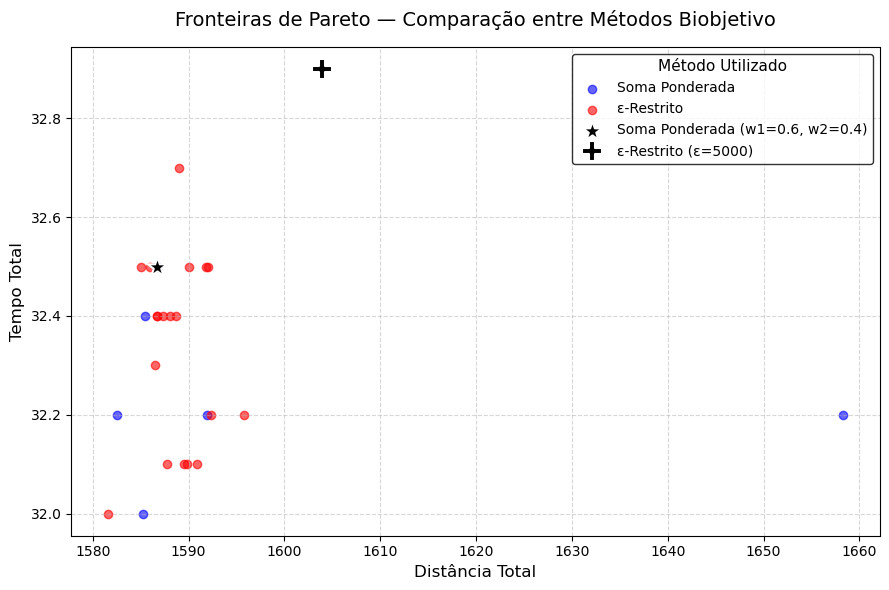

In [16]:
# ===============================================================
# ===================== EXECUÇÃO PRINCIPAL =======================
# ===============================================================

problema = Problema("distancia.csv", "tempo.csv")  # carrega as matrizes de entrada
max_iter = 5

# Cria rota inicial com heurística do vizinho mais próximo
rota0 = construtiva_vizinho_mais_proximo(problema, "distancia")

# ----- MÉTODO DA SOMA PONDERADA -----
w1, w2 = 0.6, 0.4
rota_pw, custo_pw, hist_pw = gvns_soma_ponderada(problema, rota0, w1=w1, w2=w2, lmax=1, kmax=3, max_iter=max_iter)
custo_dist = custo_rota(problema, rota_pw, "distancia")
custo_tempo = custo_rota(problema, rota_pw, "tempo")

print("===== SOMA PONDERADA =====")
print(f"Custo combinado: {custo_pw:.2f}")
print(f"Distância total: {custo_dist:.2f}")
print(f"Tempo total: {custo_tempo:.2f}\n")

# ----- MÉTODO ε-RESTRITO -----
epsilon = 5000
rota_pe, custo_pe, tempo_pe, hist_pe = gvns_epsilon(problema, rota0, epsilon=epsilon, lmax=1, kmax=3, max_iter=max_iter)

if rota_pe is not None:
    print("===== ε-RESTRITO =====")
    print(f"Distância total: {custo_pe:.2f}")
    print(f"Tempo total: {tempo_pe:.2f} (ε = {epsilon})\n")
else:
    print("Nenhuma rota encontrada que respeite o limite de tempo especificado.\n")

# ----- FRONTEIRA DE PARETO (com 5 execuções e 20 soluções por fronteira) -----
gerar_fronteiras_pareto(
    problema, rota0, n_exec=5, max_iter=max_iter,
    rota_pw=rota_pw, custo_pw=custo_pw, custo_dist=custo_dist, custo_tempo=custo_tempo,
    rota_pe=rota_pe, custo_pe=custo_pe, tempo_pe=tempo_pe, epsilon=epsilon
)
